In [173]:
import numpy as np
import pylab
import matplotlib
import matplotlib.pyplot as plt
import astropy
import astropy.io.fits as pyfits
import pyspeckit as psk
from skimage import data
#from skimage.feature import register_translation
#from skimage.feature.register_translation import _upsampled_dft
from skimage.registration import phase_cross_correlation
from skimage.registration._phase_cross_correlation import _upsampled_dft

from scipy.ndimage import fourier_shift
import matplotlib.gridspec as gridspec
from astropy.wcs import WCS

from reproject import reproject_interp

from spectral_cube import SpectralCube
import regions
from astropy.io import fits
from astropy import units as u        



#Embed plots in Jupyter window
%matplotlib inline

#Set plot fonts
matplotlib.rc('text', usetex=True)
matplotlib.rc('font', family='sans-serif')

## ALMA- VLA Alignment

In [125]:
from regions import Regions
from regions import PixCoord
from regions import RectangleSkyRegion, RectanglePixelRegion

import pylab

#offset_image = pylab.squeeze(pyfits.getdata('NGC253_H40a_2016.1.00481.c.S.fits'))
#region_offset = "box[[33.6deg, 32.6deg], [23deg, 13deg], coord=fk5"
#region = regions.Regions.parse(region_offset,format='fits')
#sc = SpectralCube.read(offset_image)
#crop_offset = sc.subcube_from_regions(region)

region_path = "/Users/mills-group/Downloads/Band3H40a/band3_region"
band3_region = Regions.read(region_path, format="crtf")

band3_path = '/Users/mills-group/Downloads/Band3H40a/NGC253_2016.1.00481.S.cont.I.tt0.pbcor.fits'
band3_cube = SpectralCube.read(band3_path)

filelabel = "NGC253_band3"
fmt_label = "Band 3"

band3_crop = band3_cube.subcube_from_regions(band3_region)
band3_crop.hdu.writeto('NGC253_2016.1.00481.S.cont.I.tt0.pbcor.fits', overwrite=True)

band3_crop_cube = SpectralCube.read(band3_path)

moment0 = band3_crop_cube.moment(order=0, how='slice')
imgshape = np.shape(moment0)

Cube is a Stokes cube, returning spectral cube for I component
Cube is a Stokes cube, returning spectral cube for I component


11.88789625 -25.288377777775565


Ignoring specified arguments in this call because figure with num: 1 already exists


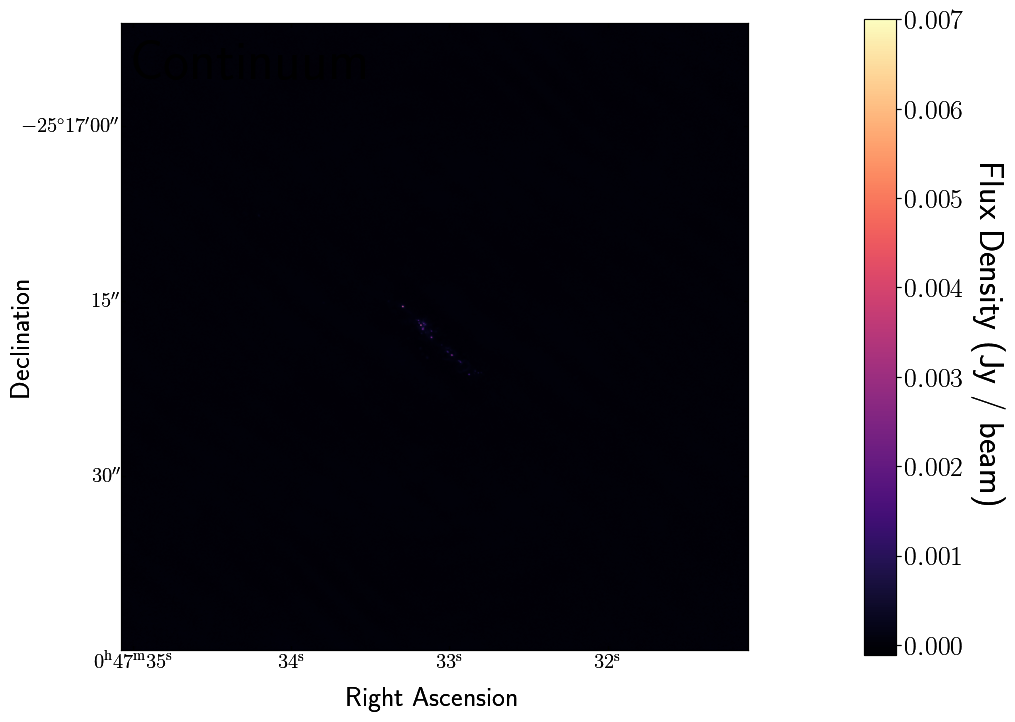

In [123]:
from regions import Regions
from regions import PixCoord
from regions import RectangleSkyRegion, RectanglePixelRegion

import pylab

image = fits.getdata(band3_path)
header = fits.getheader(band3_path)
mJy_image = image *1000
header['BUNIT'] = 'mJy/beam'
w1 = WCS(header)
w1 = w1.dropaxis(3)
w1 = w1.dropaxis(2)
image_2d = pylab.squeeze(image)
ra, dec = w1.all_pix2world(1920,1916,0)
print(ra,dec)

fig1 = pylab.figure(1,figsize=(10,10))                                              # commands to 
ax1 = pylab.subplot(projection=w1)                                                  # display the image            
RA = ax1.coords[0]                                                                  # 
Dec = ax1.coords[1]                                                                 # 
                                                                                    #
im1 = pylab.imshow(image_2d,cmap='magma')                                           #    
RA.set_ticks(size=-3)                                                               #                       
Dec.set_ticks(size=-3)                                                              #                      
pylab.xlabel('Right Ascension',fontsize=20,labelpad=1)                              # 
pylab.ylabel('Declination',fontsize=20,labelpad=0)                                  # 
ax1.tick_params(axis = 'both', which = 'major', labelsize = 15)                     # 
pylab.annotate('Continuum',fontsize=40,xy=(0.02,0.91),xycoords="axes fraction")   #
cb=pylab.colorbar(im1,fraction=0.041,pad=0.15)                                      # change padding to make room
cb.set_label(label='Flux Density (Jy / beam)',fontsize=25,rotation=270,labelpad=30) #
cb.ax.tick_params(which = 'major', labelsize = 20)                                  #
pylab.show()

All-NaN slice encountered
WCS1 is missing card PV2_1
WCS1 is missing card PV2_2


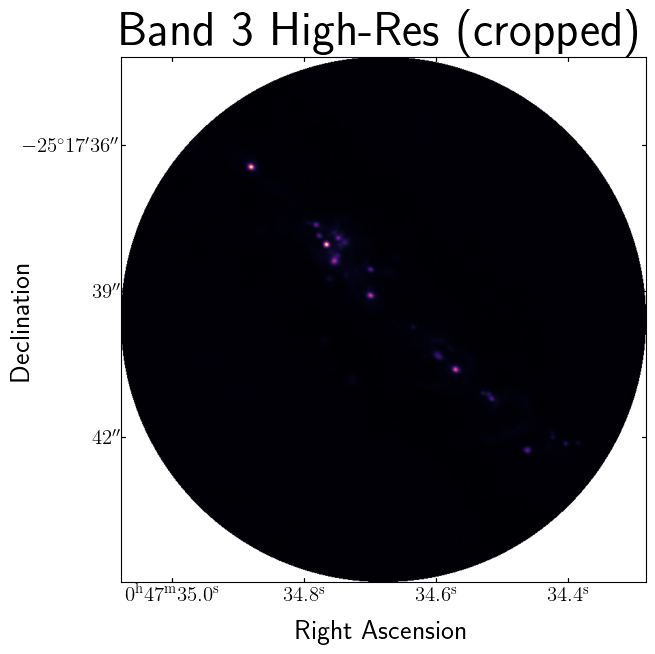

In [180]:
region_str = "circle[[11.8879deg, -25.28852deg], 0.0015deg], coord=fk5" 
region = regions.Regions.parse(region_str,format='crtf')
crop = band3_cube.subcube_from_regions(region) 
max_crop = crop.apply_numpy_function(np.nanmax,axis=0)
#max_crop = crop.moment(order=0,how='slice') 

fits.writeto('NGC253_2016.1.00481.S.cont.I.tt0.cropped.pbcor.fits', crop, header,overwrite=True)
fits.writeto('NGC253_2016.1.00481.S.cont.I.tt0.max.cropped.pbcor.fits', max_crop, header,overwrite=True)


fig1 = pylab.figure(1,figsize=(15,15))
ax1 = pylab.subplot(2,2,1,projection=w1) 
im1 = pylab.imshow(max_crop.data,cmap='magma')
RA = ax1.coords[0]                                                                  
Dec = ax1.coords[1]
RA.set_ticks(size=-3)                                                                                      
Dec.set_ticks(size=-3) 
pylab.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
pylab.ylabel('Declination',fontsize=20,labelpad=0)
ax1.tick_params(axis = 'both', which = 'major', labelsize = 15)     
pylab.title('Band 3 High-Res (cropped)',fontsize=35) #xy=(0.02,0.91)) #xycoords="axes fraction") 
pylab.show()

In [108]:
region_str = "circle[[11.89deg,-25.28deg],0.008deg], coord=fk5"
region = regions.Regions.parse(region_str,format='crtf')

sky_region = region[0]

band3_cube = SpectralCube.read(band3_path)
crop = band3_cube.subcube_from_regions(region)
print(np.shape(crop))
header = fits.getheader(band3_path)
w1 = WCS(header)
ra, dec = w1.all_pix2world(1920,1916,0)
print(ra,dec)
crop = pylab.squeeze(band3_cube)

wcs_2d = w1.celestial
pixel_region = sky_region.to_pixel(wcs_2d)
crop = pylab.squeeze(band3_cube)



fig1 = pylab.figure(1,figsize=(8,8))
ax1 = pylab.subplot(1,1,1,projection=wcs_2d) 
im1 = pylab.imshow(moment0.data,cmap='magma')
pylab.show()

(1, 1827, 3476)
()


Cube is a Stokes cube, returning spectral cube for I component


TypeError: WCS projection has 4 dimensions, so expected 2 (an Nx4 array and the origin argument) or 5 arguments (the position in each dimension, and the origin argument). Instead, 3 arguments were given.

In [38]:
#Band 3 continuum is regridded to match the 36 GHz image
#36 GHz continuum and 22 GHz continuum is smoothed to match the Band 3 continuum beam


#image = pylab.squeeze(pyfits.getdata('Band3_continuum_2.5pc_regrid.fits'))
#image2 = pylab.squeeze(pyfits.getdata('Band3_continuum_2.5pc_regrid.circle.fits'))

#offset_image = pylab.squeeze(pyfits.getdata('36GHz_253_cont.fits'))
#head = pyfits.getheader('36GHz_253_cont.fits')

#offset_image2 = pylab.squeeze(pyfits.getdata('22GHz_continuum_pbcor.regrid.circle.fits'))
#head2 = pyfits.getheader('22GHz_continuum_pbcor.regrid.circle.fits')

#offset_image3 = pylab.squeeze(pyfits.getdata('36GHz_253_cont.circ.fits'))
#head3 = pyfits.getheader('36GHz_253_cont.circ.fits')
#-----------------------------------------------------------------------------------------------------
image = pylab.squeeze(pyfits.getdata('NGC253_H40a_2016.1.00481.S.fits.moment.maximum'))
image2 = pylab.squeeze(pyfits.getdata('NGC253_H40a_2016.1.00481.S.fits.moment.maximum'))

offset_image = pylab.squeeze(pyfits.getdata('ngc253_cont_hires_circbeam.fits'))
head = pyfits.getheader('ngc253_cont_hires_circbeam.fits')


#offset_image2 = pylab.squeeze(pyfits.getdata('22GHz_continuum_pbcor.regrid.circle.fits'))
#head2 = pyfits.getheader('22GHz_continuum_pbcor.regrid.circle.fits')

#offset_image3 = pylab.squeeze(pyfits.getdata('36GHz_253_cont.circ.fits'))
#head3 = pyfits.getheader('36GHz_253_cont.circ.fits')


pixel = head["CDELT1"] * (-1)*3600.0
print('Pixel Size: %1.3f "'%(pixel))

#shift, error, diffphase = register_translation(image, offset_image, 100)
#shift2, error2, diffphase2 = register_translation(image2, offset_image2, 100)
#shift3, error3, diffphase3 = register_translation(image2, offset_image3, 100)

print("image shape:", np.shape(image))
print("image2 shape:", np.shape(image2))
print("offset shape:", np.shape(offset_image))


#shift, error, diffphase = phase_cross_correlation(image, offset_image, upsample_factor=100)

shift, error, diffphase = phase_cross_correlation(image, offset_image, reference_mask=~np.isnan(image), moving_mask=~np.isnan(offset_image))

#shift2, error2, diffphase2 = phase_cross_correlation(image2, offset_image2, upsample_factor=100)
#shift3, error3, diffphase3 = phase_cross_correlation(image2, offset_image3, upsample_factor=100)

print("Detected subpixel offset (y, x): {}".format(shift))
print("Error: {}".format(error))

print('Offset from ALMA frame of reference (x,y) in arcseconds')
print('VLA 33 GHz: (%1.3f,%1.3f) +/- %1.3f'%(shift[1]*pixel,shift[0]*pixel,error*pixel))

#print("Detected subpixel offset (y, x): {}".format(shift2))
#print("Error: {}".format(error2))

#print('Offset from ALMA frame of reference (x,y) in arcseconds')
#print('VLA 22 GHz: (%1.3f,%1.3f) +/- %1.3f'%(shift2[1]*pixel,shift2[0]*pixel,error2*pixel))

#print("Detected subpixel offset (y, x): {}".format(shift3))
#print("Error: {}".format(error3))

#print('Offset from ALMA frame of reference (x,y) in arcseconds')
#print('VLA 33 GHz: (%1.3f,%1.3f) +/- %1.3f'%(shift3[1]*pixel,shift3[0]*pixel,error3*pixel))

Pixel Size: 0.005 "
image shape: (2560, 2560)
image2 shape: (2560, 2560)
offset shape: (2560, 2560)
Detected subpixel offset (y, x): [828. 623.]
Error: nan
Offset from ALMA frame of reference (x,y) in arcseconds
VLA 33 GHz: (2.866,3.809) +/- nan


## Apply Offset

In [39]:
#Shift the 36 GHz continuum image


shifted_image = fourier_shift(np.fft.fftn(offset_image), shift)
shifted_image = np.fft.ifftn(shifted_image)

pyfits.writeto('ngc253_cont_hires_circbeam.fits', shifted_image.real,head,overwrite=True)

#Shift the 22 GHz continuum image

#shifted_image2 = fourier_shift(np.fft.fftn(offset_image2), shift2)
#shifted_image2 = np.fft.ifftn(shifted_image2)

#pyfits.writeto('22GHz_253_cont_shift.fits', shifted_image2.real,head2,overwrite=True)

#Shift the circular 36 GHz continuum image

#shifted_image3 = fourier_shift(np.fft.fftn(offset_image3), shift3)
#shifted_image3 = np.fft.ifftn(shifted_image3)

#pyfits.writeto('36GHz_253_cont_circ_shift.fits', shifted_image3.real,head3,overwrite=True)


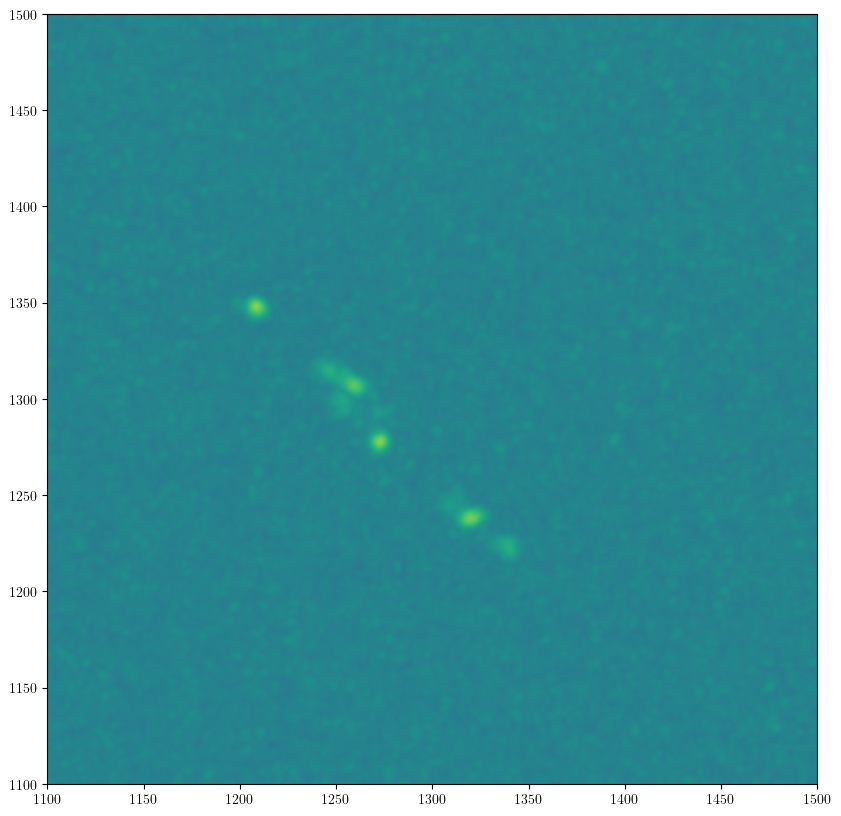

In [40]:
#Overplot images to check alignment

radio1 = pylab.squeeze(pyfits.getdata('NGC253_H40a_2016.1.00481.S.fits.moment.maximum'))
radio2 = pylab.squeeze(pyfits.getdata('ngc253_cont_hires_circbeam.fits'))
pylab.figure(1,figsize=(10,10))
pylab.imshow(radio1)
pylab.contour(radio2)
pylab.xlim(1100,1500)
pylab.ylim(1100, 1500)
pylab.show()